# 02 Baselines: imbalance fixes vs calibration and fairness

**Goal:** compare plain CE, SMOTE-NC, weighted CE, focal loss, other backbones and the post-hoc fixes (S1 prior correction, S2 group thresholds) under one threshold rule (flag the top 10% by risk).
All numbers are on the **validation** split (test is locked until Phase 6): mean over 3 seeds, 95% CI from 1,000 paired stratified bootstrap resamples.

In [1]:
import json, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.utils import load_config, resolve
from src.data.tensors import load_arrays
from src.eval.metrics import ece_equal_freq

cfg = load_config('configs/train.yaml')
runs = sorted(p for p in resolve(cfg['runs_dir']).glob('*_phase2') if (p / 'results.csv').exists())
RUN = runs[-1]
print('run folder:', RUN.name)
res = pd.read_csv(RUN / 'results.csv').set_index('key')
meta = json.loads((RUN / 'run_meta.json').read_text())
print('git', meta['git_hash'][:10], '| seeds', meta['seeds'], '|', meta['split'])
val, _ = load_arrays(cfg, 'val')

run folder: 20261101T052529Z_phase2
git f00d2664bf | seeds [0, 1, 2] | validation only


## Main table (shared rule: top 10% flagged)

In [2]:
def fmt(k, m, d=3):
    return res.apply(lambda r: f"{r[m]:.{d}f} [{r[m+'_lo']:.{d}f}, {r[m+'_hi']:.{d}f}]", axis=1)
cols = {'auc_roc': 'AUC-ROC', 'auc_pr': 'AUC-PR', 'ks': 'KS', 'recall': 'Recall@10%',
        'dir': 'DIR', 'eod': 'EOD', 'ece': 'ECE', 'worst_group_ece': 'Worst-group ECE',
        'brier': 'Brier'}
main = pd.DataFrame({v: fmt(None, k) for k, v in cols.items()})
main.insert(0, 'arm', res['arm'])
main

,arm,AUC-ROC,AUC-PR,KS,Recall@10%,DIR,EOD,ECE,Worst-group ECE,Brier
key,,,,,,,,,,
a0,A0,"0.746 [0.737, 0.754]","0.221 [0.210, 0.232]","0.367 [0.359, 0.387]","0.316 [0.302, 0.330]","0.942 [0.936, 0.948]","0.088 [0.060, 0.116]","0.004 [0.005, 0.007]","0.010 [0.010, 0.013]","0.069 [0.068, 0.069]"
a1,A1,"0.686 [0.677, 0.695]","0.166 [0.158, 0.174]","0.275 [0.264, 0.293]","0.252 [0.238, 0.265]","0.935 [0.929, 0.942]","0.109 [0.085, 0.136]","0.152 [0.151, 0.154]","0.169 [0.166, 0.173]","0.120 [0.119, 0.122]"
a2,A2,"0.746 [0.737, 0.754]","0.220 [0.210, 0.232]","0.366 [0.353, 0.382]","0.320 [0.306, 0.333]","0.943 [0.936, 0.950]","0.086 [0.058, 0.115]","0.342 [0.341, 0.344]","0.359 [0.356, 0.362]","0.205 [0.204, 0.207]"
a3,A3,"0.714 [0.706, 0.723]","0.198 [0.189, 0.208]","0.321 [0.307, 0.337]","0.296 [0.282, 0.309]","0.929 [0.923, 0.935]","0.111 [0.086, 0.137]","0.318 [0.317, 0.320]","0.338 [0.335, 0.341]","0.190 [0.188, 0.191]"
a4,A4,"0.747 [0.739, 0.755]","0.222 [0.212, 0.233]","0.368 [0.354, 0.383]","0.320 [0.305, 0.333]","0.936 [0.930, 0.942]","0.099 [0.071, 0.127]","0.345 [0.344, 0.347]","0.364 [0.361, 0.367]","0.206 [0.205, 0.208]"
a5,A5,"0.745 [0.737, 0.753]","0.219 [0.210, 0.230]","0.367 [0.353, 0.382]","0.319 [0.305, 0.333]","0.944 [0.938, 0.951]","0.091 [0.062, 0.119]","0.372 [0.371, 0.373]","0.373 [0.372, 0.375]","0.211 [0.210, 0.212]"
s1,S1,"0.746 [0.737, 0.754]","0.220 [0.210, 0.232]","0.366 [0.353, 0.382]","0.320 [0.306, 0.333]","0.943 [0.936, 0.950]","0.086 [0.058, 0.115]","0.004 [0.004, 0.006]","0.008 [0.009, 0.012]","0.069 [0.068, 0.069]"
s2,S2,"0.746 [0.737, 0.754]","0.220 [0.210, 0.232]","0.366 [0.353, 0.382]","0.315 [0.300, 0.329]","0.988 [0.982, 0.994]","0.004 [0.004, 0.033]","0.004 [0.004, 0.006]","0.008 [0.009, 0.012]","0.069 [0.068, 0.069]"
s2_fairlearn,S2 fairlearn native (not rate-matched),"0.746 [0.737, 0.754]","0.220 [0.210, 0.232]","0.366 [0.353, 0.382]","0.666 [0.652, 0.680]","0.983 [0.971, 0.995]","0.002 [0.004, 0.032]","0.004 [0.004, 0.006]","0.008 [0.009, 0.012]","0.069 [0.068, 0.069]"


## Imbalance damages calibration; prior correction repairs it

In [3]:
keys = ['a0', 'a1', 'a2', 's1']
cal = res.loc[keys, ['ece', 'worst_group_ece', 'cal_slope', 'cal_intercept', 'brier',
                      'recall_at_0.5', 'flag_rate_at_0.5']].round(4)
cal.columns = ['ECE', 'worst-group ECE', 'cal slope', 'cal intercept', 'Brier',
               'recall at p>0.5 (diagnostic)', 'flag rate at p>0.5 (diagnostic)']
cal

,ECE,worst-group ECE,cal slope,cal intercept,Brier,recall at p>0.5 (diagnostic),flag rate at p>0.5 (diagnostic)
key,,,,,,,
a0,0.0042,0.0099,0.9703,-0.0512,0.0688,0.0030,0.0005
a1,0.1523,0.1691,0.4788,-1.8480,0.1201,0.3079,0.1323
a2,0.3424,0.3593,0.9774,-2.4356,0.2053,0.6782,0.3455
s1,0.0035,0.0083,0.9774,-0.0581,0.0688,0.0028,0.0005


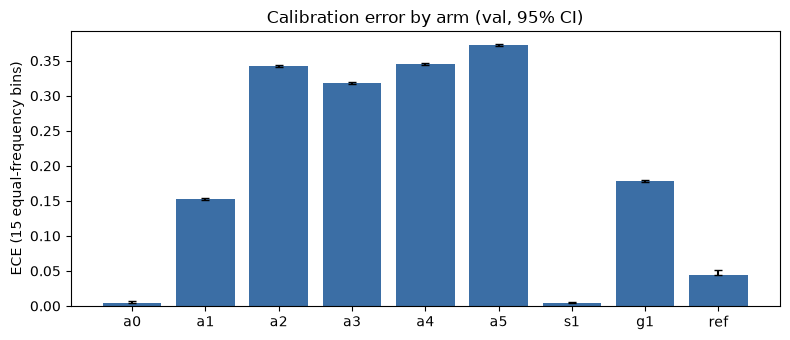

In [4]:
order = [k for k in ['a0','a1','a2','a3','a4','a5','s1','g1','ref'] if k in res.index]
fig, ax = plt.subplots(figsize=(8, 3.5))
y = res.loc[order, 'ece']
err = [(y - res.loc[order, 'ece_lo']).clip(lower=0), (res.loc[order, 'ece_hi'] - y).clip(lower=0)]
ax.bar(order, y, yerr=err, color='#3b6ea5', capsize=3)
ax.set_ylabel('ECE (15 equal-frequency bins)'); ax.set_title('Calibration error by arm (val, 95% CI)')
plt.tight_layout(); plt.show()

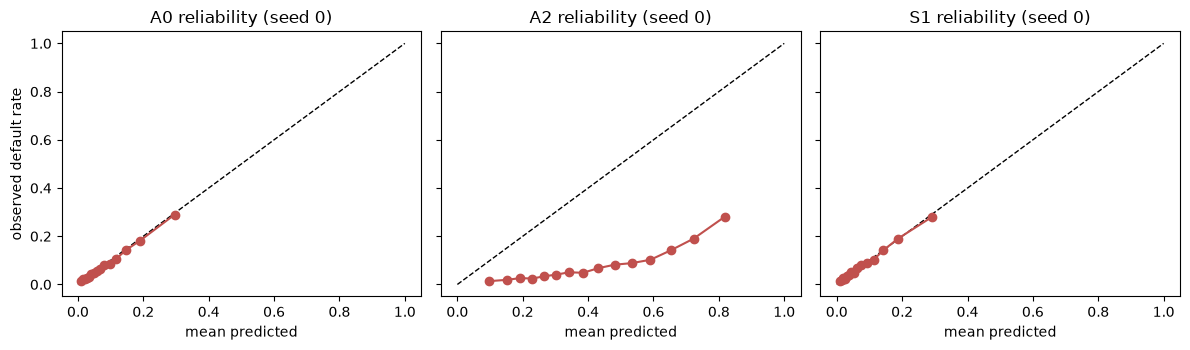

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True, sharey=True)
for a_, key in zip(ax, ['a0', 'a2', 's1']):
    p = np.load(RUN / key / 'seed_0' / 'val_prob.npy')
    order_ = np.argsort(p); idx = np.array_split(order_, 15)
    mp = [p[i].mean() for i in idx]; my = [val.y[i].mean() for i in idx]
    a_.plot([0, 1], [0, 1], 'k--', lw=1); a_.plot(mp, my, 'o-', color='#c0504d')
    a_.set_title(f"{key.upper()} reliability (seed 0)"); a_.set_xlabel('mean predicted')
ax[0].set_ylabel('observed default rate')
plt.tight_layout(); plt.show()

## Does the imbalance fix change group-wise calibration? (A0 per gender)

In [6]:
g = res.loc[['a0', 'a1', 'a2', 's1', 'ref'], ['ece_f', 'ece_m', 'tpr_f', 'tpr_m', 'fpr_f', 'fpr_m']].round(4)
g.columns = ['ECE female', 'ECE male', 'TPR female', 'TPR male', 'FPR female', 'FPR male']
g

,ECE female,ECE male,TPR female,TPR male,FPR female,FPR male
key,,,,,,
a0,0.0059,0.0092,0.2784,0.3665,0.0664,0.1087
a1,0.1436,0.1691,0.2047,0.3142,0.0700,0.1196
a2,0.3337,0.3593,0.2827,0.3690,0.0665,0.1077
s1,0.0066,0.0083,0.2827,0.3690,0.0665,0.1077
ref,0.0465,0.0435,0.2417,0.2785,0.0698,0.1014


## Fairness at the shared threshold

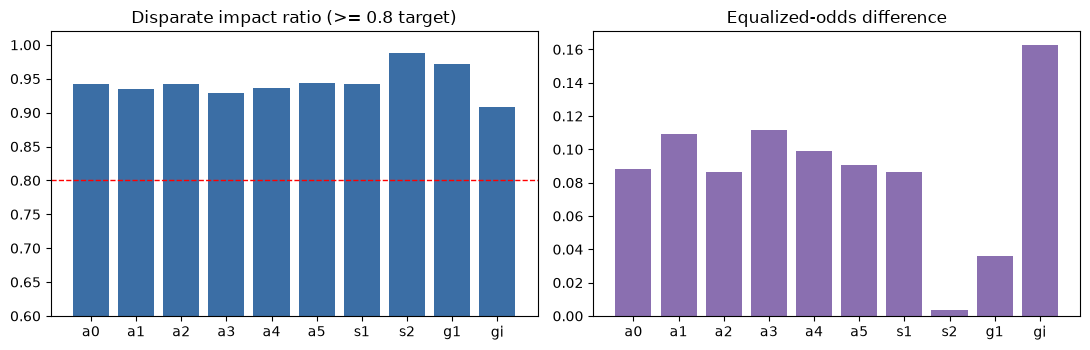

In [7]:
fo = [k for k in ['a0','a1','a2','a3','a4','a5','s1','s2','g1','gi'] if k in res.index]
fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].bar(fo, res.loc[fo, 'dir'], color='#3b6ea5'); ax[0].axhline(0.8, color='r', ls='--', lw=1)
ax[0].set_title('Disparate impact ratio (>= 0.8 target)'); ax[0].set_ylim(0.6, 1.02)
ax[1].bar(fo, res.loc[fo, 'eod'], color='#8a6fb0'); ax[1].set_title('Equalized-odds difference')
plt.tight_layout(); plt.show()

## Discrimination vs calibration trade-off per arm

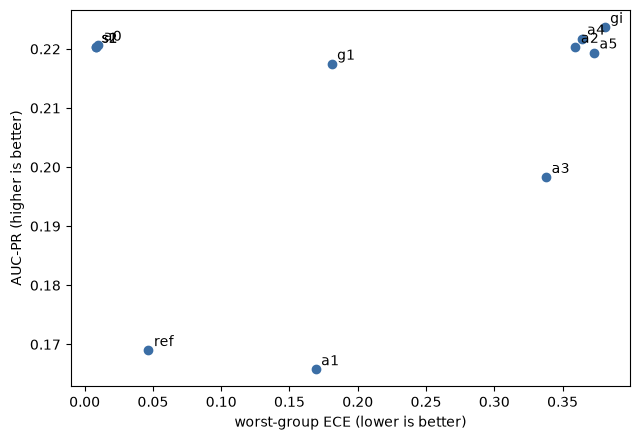

In [8]:
d = res.loc[[k for k in res.index if k not in ('s2_fairlearn',)]]
fig, ax = plt.subplots(figsize=(6.5, 4.5))
ax.scatter(d['worst_group_ece'], d['auc_pr'], color='#3b6ea5')
for k, r in d.iterrows(): ax.annotate(k, (r['worst_group_ece'], r['auc_pr']), xytext=(4, 3), textcoords='offset points')
ax.set_xlabel('worst-group ECE (lower is better)'); ax.set_ylabel('AUC-PR (higher is better)')
plt.tight_layout(); plt.show()

## Tuning and training cost

In [9]:
rows = []
for k in ['a0','a1','a2','a3','a4','a5','g1']:
    t = json.loads((RUN / k / 'tuning.json').read_text())
    s = json.loads((RUN / k / 'summary.json').read_text())['seeds']
    rows.append({'arm': k, 'best tuning AUC-PR': round(t['best_value'], 4),
                 'tuning s': round(t['seconds']), 'mean epochs': np.mean([v['epochs_run'] for v in s.values()]),
                 'mean train s': round(np.mean([v['seconds'] for v in s.values()]), 1),
                 **{p: round(v, 5) for p, v in t['best_params'].items()}})
pd.DataFrame(rows).set_index('arm')

,best tuning AUC-PR,tuning s,mean epochs,mean train s,lr,weight_decay,dropout,emb_dim,focal_gamma
arm,,,,,,,,,
a0,0.2089,38,22.333333,24.6,0.00071,0.00071,0.21960,16.0,NaN
a1,0.1612,78,8.666667,32.3,0.00122,0.00000,0.01952,32.0,NaN
a2,0.2106,31,16.333333,17.4,0.00071,0.00071,0.21960,16.0,NaN
a3,0.1778,20,28.000000,20.9,0.00204,0.00000,0.05455,NaN,NaN
a4,0.2166,8,9.333333,3.1,0.00204,0.00000,0.05455,NaN,NaN
a5,0.2113,29,14.666667,16.2,0.00071,0.00071,0.21960,16.0,1.11617
g1,0.2079,40,18.666667,24.7,0.00071,0.00071,0.21960,16.0,NaN


## What this shows

All numbers are validation-only (test is locked), 3 seeds, shared rule "flag the top 10%".

- **Weighted CE inflates probabilities; prior correction repairs it.** A0 (plain CE) is already well calibrated (ECE 0.004). A2 (weighted CE) has the same ranking quality (AUC-ROC 0.746 vs 0.746) but ECE 0.342 and a calibration intercept of about -2.4. Its recall at the naive p > 0.5 cut-off jumps from 0.3% (A0) to 68% (A2), because the model now over-predicts default. S1 (A2 minus the analytic logit shift) brings ECE back to 0.004 with identical ranking. At the shared 10% flag rate, recall is nearly the same for A0 and A2 (0.316 vs 0.320), so the "higher recall" effect only appears at a fixed probability cut-off.
- **The hypothesis "A1 (SMOTE-NC) calibrates worse than A2" is NOT supported.** A1 has ECE 0.152, better than A2's 0.342, because SMOTE-NC at ratio 0.5 raises the effective prior about 5.7 times while class weights raise it about 11.4 times. SMOTE-NC is worse on discrimination instead (AUC-ROC 0.686 vs 0.746, early stopping after 7 to 10 epochs). This gate item is reported as failed; nothing was tuned to change it.
- **Group-wise calibration of A0.** A0 is well calibrated for both groups (ECE 0.006 female, 0.009 male), consistent with the "group calibration as a byproduct of unconstrained learning" claim (Liu et al.). The imbalance fixes break it for both groups together.
- **Fairness at the shared rule is already close to the 0.8 target** for every arm (DIR 0.93 to 0.94, EOD about 0.09 for A0/A2). Women have a lower TPR (0.28 vs 0.37) and lower FPR (0.066 vs 0.109), so men are flagged more. S2 equalises these gaps (DIR 0.988, EOD 0.004) without changing AUC, but its thresholds were fit and scored on the same validation split, so that number is optimistic and needs the test split in Phase 6. The fairlearn ThresholdOptimizer picks its own operating point (about 33% flagged), so it is shown as a separate non-rate-matched row.
- **G1 (group soft-ECE loss)** lowers ECE (0.178 vs 0.342) and narrows the EOD (0.036), at a small cost in AUC-PR (0.218 vs 0.220). Because it is trained against weighted CE, it only partly cancels the inflation.
- **GI (gender included, never deployable)** gets the highest AUC-PR (0.224) but a lower DIR (0.909) and a larger EOD (0.163): adding gender makes the gap larger, not smaller.
- **Backbones.** The TabTransformer (A0/A2) is not better than the MLP (A4, AUC-PR 0.222) and beats the 1D CNN (0.198). The LightGBM reference (AUC-ROC 0.699, AUC-PR 0.169) is unexpectedly below the neural arms. The cause has not been investigated (candidates: `scale_pos_weight` with an AUC-PR early-stopping rule, no tuning), so treat REF as an untuned reference and revisit it before any claim about GBT vs TabTransformer.
- **Caveats.** Optuna used 10 trials, which is all random start-up trials for TPE, with the same sampler seed for every arm, so arms A0/A2/A5/G1 selected the same configuration. Confidence intervals come from 1,000 paired stratified bootstrap resamples of the validation set (seed variation is shown in `results.csv`). For well-calibrated arms (A0, S1) the bootstrap ECE is biased upward, so the percentile interval sits slightly above the point estimate (for example A0: 0.0042 [0.0045, 0.0066]); in the chart such error bars are clipped at zero.
